In [2]:
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

print("Python version:", sys.version)
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)
print("Scikit-learn version:", sklearn.__version__)
print("\nEnvironment is ready!")

Python version: 3.13.7 (tags/v3.13.7:bcee1c3, Aug 14 2025, 14:15:11) [MSC v.1944 64 bit (AMD64)]
Pandas version: 3.0.6
NumPy version: 2.5.4
Scikit-learn version: 1.9.1

Environment is ready!


In [3]:
from pathlib import Path

data_folder = Path("../data/raw")

print("Current notebook folder:", Path.cwd())
print("\nFiles found in data/raw:")

for file in data_folder.glob("*"):
    print(file.name)

Current notebook folder: C:\Users\LAPTOP\Desktop\Telecom-Customer-Churn-Prediction\notebooks

Files found in data/raw:


In [4]:
import pandas as pd
from pathlib import Path

csv_files = list(Path("../data/raw").glob("*.csv"))

if not csv_files:
    print("No CSV found. Check the data/raw folder.")
else:
    df1 = pd.read_csv(csv_files[0])
    print("Dataset shape:", df1.shape)
    display(df1.head())
    print("\nColumn names:")
    print(df1.columns.tolist())

No CSV found. Check the data/raw folder.


In [5]:
from pathlib import Path

data_folder = Path("../data/raw")
print("CSV files:", list(data_folder.glob("*.csv")))

CSV files: [WindowsPath('../data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv')]


In [6]:
import pandas as pd
from pathlib import Path

data_folder = Path("../data/raw")
csv_files = list(data_folder.glob("*.csv"))

if csv_files:
    df1 = pd.read_csv(csv_files[0])

    print("Dataset loaded successfully!")
    print("File:", csv_files[0].name)
    print("Rows and columns:", df1.shape)

    display(df1.head())
    print("\nColumn names:")
    print(df1.columns.tolist())
else:
    print("No CSV file found in data/raw.")

Dataset loaded successfully!
File: WA_Fn-UseC_-Telco-Customer-Churn.csv
Rows and columns: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes



Column names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


In [7]:
# 1. Check data types and missing values
print("DATASET INFORMATION")
df1.info()

# 2. Check missing values
print("\nMISSING VALUES")
print(df1.isnull().sum().sort_values(ascending=False).head(10))

# 3. Check duplicate rows
print("\nDUPLICATE ROWS:", df1.duplicated().sum())

# 4. Check churn distribution
print("\nCHURN DISTRIBUTION")
print(df1["Churn"].value_counts())

print("\nCHURN PERCENTAGE")
print((df1["Churn"].value_counts(normalize=True) * 100).round(2))

DATASET INFORMATION
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null  

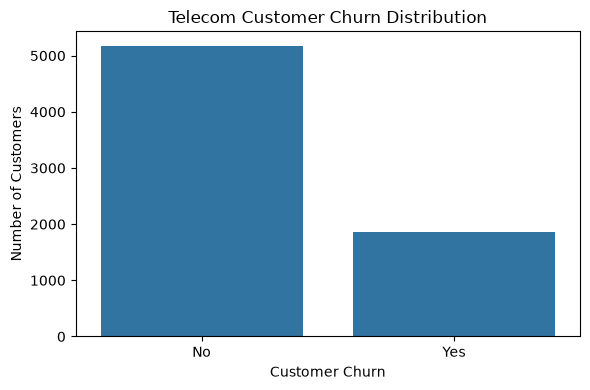

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6, 4))
sns.countplot(data=df1, x="Churn")
plt.title("Telecom Customer Churn Distribution")
plt.xlabel("Customer Churn")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

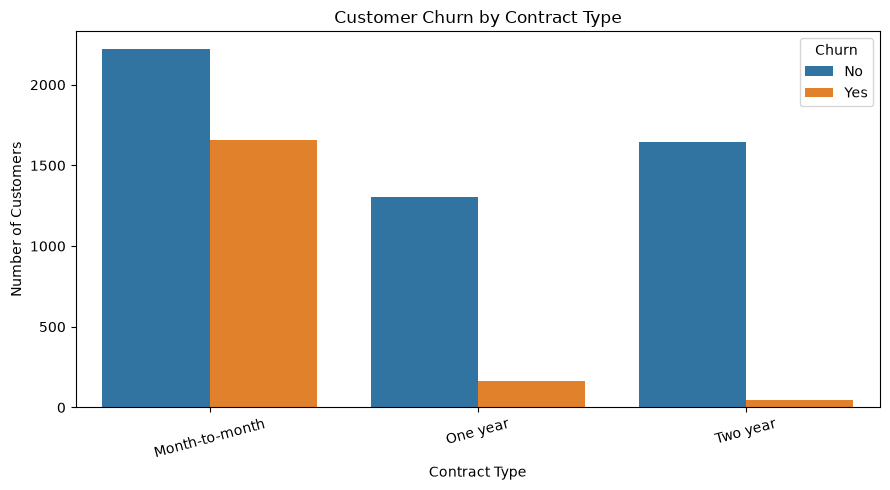

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 5))

sns.countplot(
    data=df1,
    x="Contract",
    hue="Churn"
)

plt.title("Customer Churn by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [10]:
contract_churn = pd.crosstab(
    df1["Contract"],
    df1["Churn"],
    normalize="index"
) * 100

print("Churn percentage by contract type:")
display(contract_churn.round(2))

Churn percentage by contract type:


Churn,No,Yes
Contract,,
Month-to-month,57.29,42.71
One year,88.73,11.27
Two year,97.17,2.83


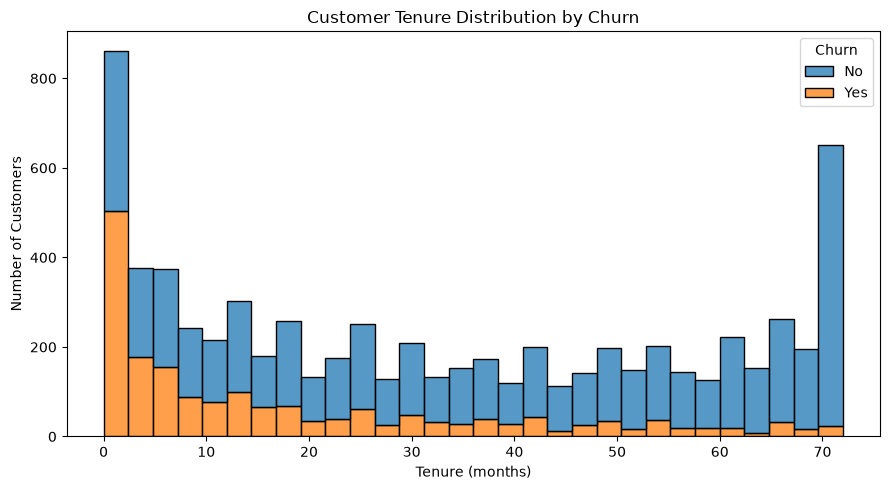

In [11]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df1,
    x="tenure",
    hue="Churn",
    bins=30,
    multiple="stack"
)

plt.title("Customer Tenure Distribution by Churn")
plt.xlabel("Tenure (months)")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

In [12]:
print("Average tenure by churn status:")
display(
    df1.groupby("Churn")["tenure"]
       .agg(["mean", "median", "count"])
       .round(2)
)

Average tenure by churn status:


,mean,median,count
Churn,,,
No,37.57,38.0,5174
Yes,17.98,10.0,1869


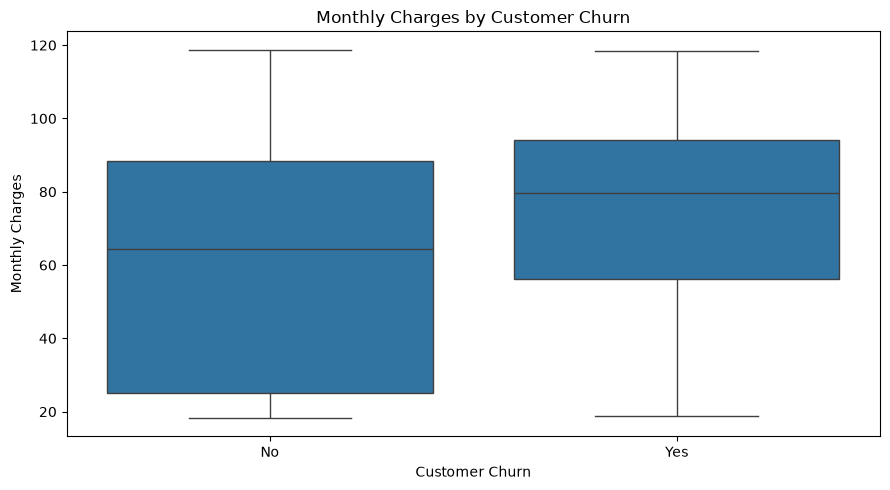

In [13]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df1,
    x="Churn",
    y="MonthlyCharges"
)

plt.title("Monthly Charges by Customer Churn")
plt.xlabel("Customer Churn")
plt.ylabel("Monthly Charges")
plt.tight_layout()
plt.show()

In [14]:
print("Monthly charges by churn status:")

display(
    df1.groupby("Churn")["MonthlyCharges"]
       .agg(["mean", "median", "min", "max"])
       .round(2)
)

Monthly charges by churn status:


,mean,median,min,max
Churn,,,,
No,61.27,64.43,18.25,118.75
Yes,74.44,79.65,18.85,118.35


In [15]:
print("Data types:")
display(df1.dtypes)

print("\nMissing values before cleaning:")
print(df1.isnull().sum().sort_values(ascending=False).head(10))

print("\nBlank TotalCharges values:")
print(
    df1["TotalCharges"]
       .astype(str)
       .str.strip()
       .eq("")
       .sum()
)

Data types:


customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object


Missing values before cleaning:
customerID         0
gender             0
SeniorCitizen      0
Partner            0
Dependents         0
tenure             0
PhoneService       0
MultipleLines      0
InternetService    0
OnlineSecurity     0
dtype: int64

Blank TotalCharges values:
11


In [16]:
# Work on a copy; keep the original dataset unchanged
df_clean = df1.copy()

# Convert TotalCharges to numeric
df_clean["TotalCharges"] = pd.to_numeric(
    df_clean["TotalCharges"],
    errors="coerce"
)

# Check missing values
print("Missing TotalCharges:", df_clean["TotalCharges"].isna().sum())

# Remove rows where TotalCharges is missing
df_clean = df_clean.dropna(subset=["TotalCharges"]).copy()

print("Original rows:", len(df1))
print("Rows after cleaning:", len(df_clean))
print("Remaining missing values:", df_clean.isnull().sum().sum())

display(df_clean.head())

Missing TotalCharges: 11
Original rows: 7043
Rows after cleaning: 7032
Remaining missing values: 0


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [17]:
from sklearn.model_selection import train_test_split

# Remove customerID because it is an identifier, not a useful predictive feature
X = df_clean.drop(columns=["Churn", "customerID"])
y = df_clean["Churn"].map({"No": 0, "Yes": 1})

print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("\nTarget distribution:")
print(y.value_counts().rename(index={0: "Stayed", 1: "Churned"}))

Features shape: (7032, 19)
Target shape: (7032,)

Target distribution:
Churn
Stayed     5163
Churned    1869
Name: count, dtype: int64


In [18]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Training churn rate:", round(y_train.mean() * 100, 2), "%")
print("Testing churn rate:", round(y_test.mean() * 100, 2), "%")

Training records: 5625
Testing records: 1407
Training churn rate: 26.58 %
Testing churn rate: 26.58 %


LOGISTIC REGRESSION — TEST RESULTS
Accuracy : 0.8038
Precision: 0.6485
Recall   : 0.5722
F1-score : 0.608
ROC-AUC  : 0.8359

Classification report:
              precision    recall  f1-score   support

      Stayed       0.85      0.89      0.87      1033
     Churned       0.65      0.57      0.61       374

    accuracy                           0.80      1407
   macro avg       0.75      0.73      0.74      1407
weighted avg       0.80      0.80      0.80      1407



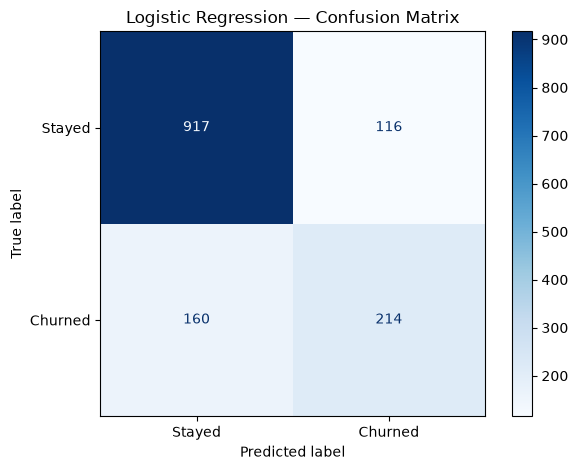

In [19]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

numeric_features = X_train.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=["number"]).columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

# ACTUAL MODEL TRAINING
logistic_model.fit(X_train, y_train)

# Evaluate on unseen test data
y_pred = logistic_model.predict(X_test)
y_prob = logistic_model.predict_proba(X_test)[:, 1]

print("LOGISTIC REGRESSION — TEST RESULTS")
print("Accuracy :", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 4))
print("Recall   :", round(recall_score(y_test, y_pred, zero_division=0), 4))
print("F1-score :", round(f1_score(y_test, y_pred, zero_division=0), 4))
print("ROC-AUC  :", round(roc_auc_score(y_test, y_prob), 4))

print("\nClassification report:")
print(classification_report(
    y_test, y_pred,
    target_names=["Stayed", "Churned"],
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    display_labels=["Stayed", "Churned"],
    cmap="Blues"
)
plt.title("Logistic Regression — Confusion Matrix")
plt.tight_layout()
plt.show()

In [20]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)
import pandas as pd

models = {
    "Decision Tree": DecisionTreeClassifier(
        max_depth=6,
        class_weight="balanced",
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )
}

results = []

# Include the Logistic Regression results already calculated
results.append({
    "Model": "Logistic Regression",
    "Accuracy": accuracy_score(y_test, logistic_model.predict(X_test)),
    "Precision": precision_score(
        y_test, logistic_model.predict(X_test), zero_division=0
    ),
    "Recall": recall_score(
        y_test, logistic_model.predict(X_test), zero_division=0
    ),
    "F1-score": f1_score(
        y_test, logistic_model.predict(X_test), zero_division=0
    ),
    "ROC-AUC": roc_auc_score(
        y_test, logistic_model.predict_proba(X_test)[:, 1]
    )
})

trained_models = {"Logistic Regression": logistic_model}

for name, classifier in models.items():
    pipeline = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("classifier", classifier)
    ])

    print(f"Training {name}...")
    pipeline.fit(X_train, y_train)

    predictions = pipeline.predict(X_test)
    probabilities = pipeline.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_test, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, probabilities)
    })

    trained_models[name] = pipeline

results_df = pd.DataFrame(results).set_index("Model")

print("\nMODEL COMPARISON")
display(results_df.round(4))

Training Decision Tree...
Training Random Forest...

MODEL COMPARISON


,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Logistic Regression,0.8038,0.6485,0.5722,0.6080,0.8359
Decision Tree,0.7335,0.4992,0.7995,0.6146,0.8182
Random Forest,0.7676,0.5535,0.6497,0.5978,0.8146


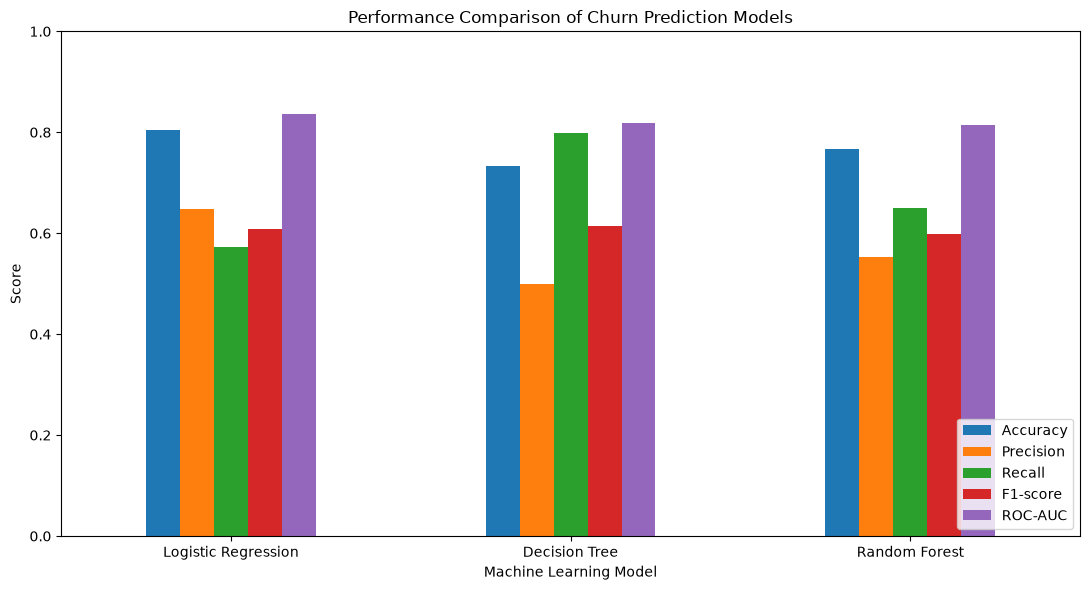

In [21]:
import matplotlib.pyplot as plt

metrics = ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]

results_df[metrics].plot(
    kind="bar",
    figsize=(11, 6),
    ylim=(0, 1)
)

plt.title("Performance Comparison of Churn Prediction Models")
plt.ylabel("Score")
plt.xlabel("Machine Learning Model")
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [22]:
from pathlib import Path
import joblib

model_folder = Path("../models")
model_folder.mkdir(parents=True, exist_ok=True)

for name, model in trained_models.items():
    filename = name.lower().replace(" ", "_") + ".joblib"
    joblib.dump(model, model_folder / filename)
    print(f"Saved: {model_folder / filename}")

Saved: ..\models\logistic_regression.joblib
Saved: ..\models\decision_tree.joblib
Saved: ..\models\random_forest.joblib


In [23]:
from pathlib import Path

data_folder = Path("../data/raw")

print("CSV files found:\n")

for file in sorted(data_folder.glob("*.csv")):
    print(f"{file.name} — {file.stat().st_size / (1024 * 1024):.2f} MB")

CSV files found:

Telecom - Prediction Data.csv — 4.95 MB
Telecom Data.csv — 12.75 MB
WA_Fn-UseC_-Telco-Customer-Churn.csv — 0.93 MB


In [24]:
import pandas as pd
from pathlib import Path

data_folder = Path("../data/raw")

for file in sorted(data_folder.glob("*.csv")):
    if file.name == "WA_Fn-UseC_-Telco-Customer-Churn.csv":
        continue

    print("\n" + "=" * 60)
    print("FILE:", file.name)

    data = pd.read_csv(file, nrows=5)

    print("Columns:", data.columns.tolist())
    display(data.head())


FILE: Telecom - Prediction Data.csv
Columns: ['CustomerID', 'Churn', 'MonthlyRevenue', 'MonthlyMinutes', 'TotalRecurringCharge', 'DirectorAssistedCalls', 'OverageMinutes', 'RoamingCalls', 'PercChangeMinutes', 'PercChangeRevenues', 'DroppedCalls', 'BlockedCalls', 'UnansweredCalls', 'CustomerCareCalls', 'ThreewayCalls', 'ReceivedCalls', 'OutboundCalls', 'InboundCalls', 'PeakCallsInOut', 'OffPeakCallsInOut', 'DroppedBlockedCalls', 'CallForwardingCalls', 'CallWaitingCalls', 'MonthsInService', 'UniqueSubs', 'ActiveSubs', 'ServiceArea', 'Handsets', 'HandsetModels', 'CurrentEquipmentDays', 'AgeHH1', 'AgeHH2', 'ChildrenInHH', 'HandsetRefurbished', 'HandsetWebCapable', 'TruckOwner', 'RVOwner', 'Homeownership', 'BuysViaMailOrder', 'RespondsToMailOffers', 'OptOutMailings', 'NonUSTravel', 'OwnsComputer', 'HasCreditCard', 'RetentionCalls', 'RetentionOffersAccepted', 'NewCellphoneUser', 'NotNewCellphoneUser', 'ReferralsMadeBySubscriber', 'IncomeGroup', 'OwnsMotorcycle', 'AdjustmentsToCreditRating',

,CustomerID,Churn,MonthlyRevenue,MonthlyMinutes,TotalRecurringCharge,DirectorAssistedCalls,OverageMinutes,RoamingCalls,PercChangeMinutes,PercChangeRevenues,...,ReferralsMadeBySubscriber,IncomeGroup,OwnsMotorcycle,AdjustmentsToCreditRating,HandsetPrice,MadeCallToRetentionTeam,CreditRating,PrizmCode,Occupation,MaritalStatus
0,3000006,NaN,57.49,483,37,0.25,23,0.0,532,51.0,...,0,5,No,1,150,No,5-Low,Other,Other,No
1,3000018,NaN,55.23,570,72,0.00,0,0.0,38,0.0,...,0,6,No,2,80,No,1-Highest,Other,Professional,No
2,3000034,NaN,97.34,1039,50,4.95,420,0.0,198,23.3,...,0,4,No,3,10,No,3-Good,Suburban,Crafts,Yes
3,3000070,NaN,35.59,153,30,0.00,16,0.0,30,7.3,...,0,4,No,1,200,No,1-Highest,Other,Other,No
4,3000074,NaN,55.27,1213,50,0.74,0,1.3,169,1.0,...,0,3,No,0,10,No,1-Highest,Suburban,Other,No



FILE: Telecom Data.csv
Columns: ['CustomerID', 'Churn', 'MonthlyRevenue', 'MonthlyMinutes', 'TotalRecurringCharge', 'DirectorAssistedCalls', 'OverageMinutes', 'RoamingCalls', 'PercChangeMinutes', 'PercChangeRevenues', 'DroppedCalls', 'BlockedCalls', 'UnansweredCalls', 'CustomerCareCalls', 'ThreewayCalls', 'ReceivedCalls', 'OutboundCalls', 'InboundCalls', 'PeakCallsInOut', 'OffPeakCallsInOut', 'DroppedBlockedCalls', 'CallForwardingCalls', 'CallWaitingCalls', 'MonthsInService', 'UniqueSubs', 'ActiveSubs', 'ServiceArea', 'Handsets', 'HandsetModels', 'CurrentEquipmentDays', 'AgeHH1', 'AgeHH2', 'ChildrenInHH', 'HandsetRefurbished', 'HandsetWebCapable', 'TruckOwner', 'RVOwner', 'Homeownership', 'BuysViaMailOrder', 'RespondsToMailOffers', 'OptOutMailings', 'NonUSTravel', 'OwnsComputer', 'HasCreditCard', 'RetentionCalls', 'RetentionOffersAccepted', 'NewCellphoneUser', 'NotNewCellphoneUser', 'ReferralsMadeBySubscriber', 'IncomeGroup', 'OwnsMotorcycle', 'AdjustmentsToCreditRating', 'HandsetPric

,CustomerID,Churn,MonthlyRevenue,MonthlyMinutes,TotalRecurringCharge,DirectorAssistedCalls,OverageMinutes,RoamingCalls,PercChangeMinutes,PercChangeRevenues,...,ReferralsMadeBySubscriber,IncomeGroup,OwnsMotorcycle,AdjustmentsToCreditRating,HandsetPrice,MadeCallToRetentionTeam,CreditRating,PrizmCode,Occupation,MaritalStatus
0,3000002,Yes,24.00,219,22,0.25,0,0,-157,-19.0,...,0,4,No,0,30,Yes,1-Highest,Suburban,Professional,No
1,3000010,Yes,16.99,10,17,0.00,0,0,-4,0.0,...,0,5,No,0,30,No,4-Medium,Suburban,Professional,Yes
2,3000014,No,38.00,8,38,0.00,0,0,-2,0.0,...,0,6,No,0,Unknown,No,3-Good,Town,Crafts,Yes
3,3000022,No,82.28,1312,75,1.24,0,0,157,8.1,...,0,6,No,0,10,No,4-Medium,Other,Other,No
4,3000026,Yes,17.14,0,17,0.00,0,0,0,-0.2,...,0,9,No,1,10,No,1-Highest,Other,Professional,Yes


In [25]:
from pathlib import Path
import pandas as pd

data_folder = Path("../data/raw")
file_path = data_folder / "Telecom Data.csv"

df2 = pd.read_csv(file_path)

print("Dataset 2 loaded successfully!")
print("Shape:", df2.shape)

print("\nChurn distribution:")
print(df2["Churn"].value_counts(dropna=False))

print("\nMissing values:")
print(df2.isnull().sum().sort_values(ascending=False).head(15))

print("\nDuplicate rows:", df2.duplicated().sum())

print("\nFirst five rows:")
display(df2.head())

Dataset 2 loaded successfully!
Shape: (51047, 58)

Churn distribution:
Churn
No     36336
Yes    14711
Name: count, dtype: int64

Missing values:
AgeHH1                   909
AgeHH2                   909
PercChangeRevenues       367
PercChangeMinutes        367
DirectorAssistedCalls    156
TotalRecurringCharge     156
RoamingCalls             156
OverageMinutes           156
MonthlyRevenue           156
MonthlyMinutes           156
ServiceArea               24
Handsets                   1
HandsetModels              1
CurrentEquipmentDays       1
DroppedCalls               0
dtype: int64

Duplicate rows: 0

First five rows:


,CustomerID,Churn,MonthlyRevenue,MonthlyMinutes,TotalRecurringCharge,DirectorAssistedCalls,OverageMinutes,RoamingCalls,PercChangeMinutes,PercChangeRevenues,...,ReferralsMadeBySubscriber,IncomeGroup,OwnsMotorcycle,AdjustmentsToCreditRating,HandsetPrice,MadeCallToRetentionTeam,CreditRating,PrizmCode,Occupation,MaritalStatus
0,3000002,Yes,24.00,219.0,22.0,0.25,0.0,0.0,-157.0,-19.0,...,0,4,No,0,30,Yes,1-Highest,Suburban,Professional,No
1,3000010,Yes,16.99,10.0,17.0,0.00,0.0,0.0,-4.0,0.0,...,0,5,No,0,30,No,4-Medium,Suburban,Professional,Yes
2,3000014,No,38.00,8.0,38.0,0.00,0.0,0.0,-2.0,0.0,...,0,6,No,0,Unknown,No,3-Good,Town,Crafts,Yes
3,3000022,No,82.28,1312.0,75.0,1.24,0.0,0.0,157.0,8.1,...,0,6,No,0,10,No,4-Medium,Other,Other,No
4,3000026,Yes,17.14,0.0,17.0,0.00,0.0,0.0,0.0,-0.2,...,0,9,No,1,10,No,1-Highest,Other,Professional,Yes


In [26]:
missing_summary = pd.DataFrame({
    "Missing Count": df2.isnull().sum(),
    "Missing Percentage": (
        df2.isnull().mean() * 100
    ).round(2)
})

display(
    missing_summary[missing_summary["Missing Count"] > 0]
    .sort_values("Missing Count", ascending=False)
)

,Missing Count,Missing Percentage
AgeHH2,909,1.78
AgeHH1,909,1.78
PercChangeRevenues,367,0.72
PercChangeMinutes,367,0.72
MonthlyRevenue,156,0.31
MonthlyMinutes,156,0.31
RoamingCalls,156,0.31
OverageMinutes,156,0.31
DirectorAssistedCalls,156,0.31
TotalRecurringCharge,156,0.31


In [27]:
print("All Dataset 2 columns:")
for column in df2.columns:
    print(column)

All Dataset 2 columns:
CustomerID
Churn
MonthlyRevenue
MonthlyMinutes
TotalRecurringCharge
DirectorAssistedCalls
OverageMinutes
RoamingCalls
PercChangeMinutes
PercChangeRevenues
DroppedCalls
BlockedCalls
UnansweredCalls
CustomerCareCalls
ThreewayCalls
ReceivedCalls
OutboundCalls
InboundCalls
PeakCallsInOut
OffPeakCallsInOut
DroppedBlockedCalls
CallForwardingCalls
CallWaitingCalls
MonthsInService
UniqueSubs
ActiveSubs
ServiceArea
Handsets
HandsetModels
CurrentEquipmentDays
AgeHH1
AgeHH2
ChildrenInHH
HandsetRefurbished
HandsetWebCapable
TruckOwner
RVOwner
Homeownership
BuysViaMailOrder
RespondsToMailOffers
OptOutMailings
NonUSTravel
OwnsComputer
HasCreditCard
RetentionCalls
RetentionOffersAccepted
NewCellphoneUser
NotNewCellphoneUser
ReferralsMadeBySubscriber
IncomeGroup
OwnsMotorcycle
AdjustmentsToCreditRating
HandsetPrice
MadeCallToRetentionTeam
CreditRating
PrizmCode
Occupation
MaritalStatus


In [28]:
import pandas as pd
from sklearn.model_selection import train_test_split

# Make a separate copy; preserve the original dataset
df2_clean = df2.copy()

# Remove rows where the target label is missing
df2_clean = df2_clean.dropna(subset=["Churn"]).copy()

# Standardize target labels
df2_clean["Churn"] = (
    df2_clean["Churn"]
    .astype(str)
    .str.strip()
    .str.lower()
    .map({"yes": 1, "no": 0})
)

# Remove any rows with unrecognized target labels
df2_clean = df2_clean.dropna(subset=["Churn"]).copy()
df2_clean["Churn"] = df2_clean["Churn"].astype(int)

# Remove identifier from features
X2 = df2_clean.drop(columns=["Churn", "CustomerID"], errors="ignore")
y2 = df2_clean["Churn"]

X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2,
    y2,
    test_size=0.20,
    random_state=42,
    stratify=y2
)

print("Dataset 2 prepared successfully!")
print("Total labelled rows:", len(df2_clean))
print("Training rows:", len(X2_train))
print("Testing rows:", len(X2_test))
print("Number of features:", X2.shape[1])
print("\nTarget distribution:")
print(y2.value_counts().rename(index={0: "Stayed", 1: "Churned"}))

Dataset 2 prepared successfully!
Total labelled rows: 51047
Training rows: 40837
Testing rows: 10210
Number of features: 56

Target distribution:
Churn
Stayed     36336
Churned    14711
Name: count, dtype: int64


In [29]:
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)
import pandas as pd

# Identify numeric and categorical columns in Dataset 2
num2 = X2_train.select_dtypes(include="number").columns.tolist()
cat2 = X2_train.select_dtypes(exclude="number").columns.tolist()

# Preprocessing for Dataset 2
preprocessor2 = ColumnTransformer([
    ("numeric", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), num2),
    ("categorical", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), cat2)
])

models2 = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000, class_weight="balanced"
    ),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=8, class_weight="balanced", random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=150,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )
}

results2 = []
trained_models2 = {}

for name, classifier in models2.items():
    print(f"Training {name} on Dataset 2...")

    model = Pipeline([
        ("preprocessor", clone(preprocessor2)),
        ("classifier", classifier)
    ])

    model.fit(X2_train, y2_train)

    pred = model.predict(X2_test)
    prob = model.predict_proba(X2_test)[:, 1]

    results2.append({
        "Model": name,
        "Accuracy": accuracy_score(y2_test, pred),
        "Precision": precision_score(y2_test, pred, zero_division=0),
        "Recall": recall_score(y2_test, pred, zero_division=0),
        "F1-score": f1_score(y2_test, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y2_test, prob)
    })

    trained_models2[name] = model

results2_df = pd.DataFrame(results2).set_index("Model")

print("\nDATASET 2 — MODEL COMPARISON")
display(results2_df.round(4))

Training Logistic Regression on Dataset 2...
Training Decision Tree on Dataset 2...
Training Random Forest on Dataset 2...

DATASET 2 — MODEL COMPARISON


,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Logistic Regression,0.5793,0.3566,0.5717,0.4392,0.6117
Decision Tree,0.5920,0.3736,0.6145,0.4647,0.6319
Random Forest,0.7071,0.4831,0.2379,0.3188,0.6586


In [30]:
from pathlib import Path
import joblib

model_folder = Path("../models")
model_folder.mkdir(parents=True, exist_ok=True)

for name, model in trained_models2.items():
    filename = "dataset2_" + name.lower().replace(" ", "_") + ".joblib"
    joblib.dump(model, model_folder / filename)
    print("Saved:", model_folder / filename)

Saved: ..\models\dataset2_logistic_regression.joblib
Saved: ..\models\dataset2_decision_tree.joblib
Saved: ..\models\dataset2_random_forest.joblib


In [31]:
from pathlib import Path
import pandas as pd

data_folder = Path("../data/raw")

for filename in ["train.csv", "test.csv", "sampleSubmission.csv"]:
    file_path = data_folder / filename

    print("\n" + "=" * 50)
    print("FILE:", filename)

    if file_path.exists():
        data = pd.read_csv(file_path)

        print("Shape:", data.shape)
        print("Columns:", data.columns.tolist())
        display(data.head(3))
    else:
        print("File not found. Check data/raw.")


FILE: train.csv
Shape: (4250, 20)
Columns: ['state', 'account_length', 'area_code', 'international_plan', 'voice_mail_plan', 'number_vmail_messages', 'total_day_minutes', 'total_day_calls', 'total_day_charge', 'total_eve_minutes', 'total_eve_calls', 'total_eve_charge', 'total_night_minutes', 'total_night_calls', 'total_night_charge', 'total_intl_minutes', 'total_intl_calls', 'total_intl_charge', 'number_customer_service_calls', 'churn']


,state,account_length,area_code,international_plan,voice_mail_plan,number_vmail_messages,total_day_minutes,total_day_calls,total_day_charge,total_eve_minutes,total_eve_calls,total_eve_charge,total_night_minutes,total_night_calls,total_night_charge,total_intl_minutes,total_intl_calls,total_intl_charge,number_customer_service_calls,churn
0,OH,107,area_code_415,no,yes,26,161.6,123,27.47,195.5,103,16.62,254.4,103,11.45,13.7,3,3.70,1,no
1,NJ,137,area_code_415,no,no,0,243.4,114,41.38,121.2,110,10.30,162.6,104,7.32,12.2,5,3.29,0,no
2,OH,84,area_code_408,yes,no,0,299.4,71,50.90,61.9,88,5.26,196.9,89,8.86,6.6,7,1.78,2,no



FILE: test.csv
Shape: (750, 20)
Columns: ['id', 'state', 'account_length', 'area_code', 'international_plan', 'voice_mail_plan', 'number_vmail_messages', 'total_day_minutes', 'total_day_calls', 'total_day_charge', 'total_eve_minutes', 'total_eve_calls', 'total_eve_charge', 'total_night_minutes', 'total_night_calls', 'total_night_charge', 'total_intl_minutes', 'total_intl_calls', 'total_intl_charge', 'number_customer_service_calls']


,id,state,account_length,area_code,international_plan,voice_mail_plan,number_vmail_messages,total_day_minutes,total_day_calls,total_day_charge,total_eve_minutes,total_eve_calls,total_eve_charge,total_night_minutes,total_night_calls,total_night_charge,total_intl_minutes,total_intl_calls,total_intl_charge,number_customer_service_calls
0,1,KS,128,area_code_415,no,yes,25,265.1,110,45.07,197.4,99,16.78,244.7,91,11.01,10.0,3,2.70,1
1,2,AL,118,area_code_510,yes,no,0,223.4,98,37.98,220.6,101,18.75,203.9,118,9.18,6.3,6,1.70,0
2,3,IA,62,area_code_415,no,no,0,120.7,70,20.52,307.2,76,26.11,203.0,99,9.14,13.1,6,3.54,4



FILE: sampleSubmission.csv
Shape: (750, 2)
Columns: ['id', 'churn']


,id,churn
0,1,yes
1,2,no
2,3,no


In [32]:
train3 = pd.read_csv("../data/raw/train.csv")

print("Dataset 3 shape:", train3.shape)
print("\nChurn distribution:")
print(train3["churn"].value_counts(dropna=False))

print("\nChurn percentage:")
print(
    (train3["churn"].value_counts(normalize=True) * 100).round(2)
)

print("\nMissing values:")
print(train3.isnull().sum().sort_values(ascending=False).head(10))

print("\nDuplicate rows:", train3.duplicated().sum())

Dataset 3 shape: (4250, 20)

Churn distribution:
churn
no     3652
yes     598
Name: count, dtype: int64

Churn percentage:
churn
no     85.93
yes    14.07
Name: proportion, dtype: float64

Missing values:
state                    0
account_length           0
area_code                0
international_plan       0
voice_mail_plan          0
number_vmail_messages    0
total_day_minutes        0
total_day_calls          0
total_day_charge         0
total_eve_minutes        0
dtype: int64

Duplicate rows: 0


In [33]:
import pandas as pd
from sklearn.model_selection import train_test_split

train3 = pd.read_csv("../data/raw/train.csv")

# Standardize target labels
train3["churn"] = (
    train3["churn"].astype(str).str.strip().str.lower()
)

# Convert target: no = 0, yes = 1
train3["churn"] = train3["churn"].map({"no": 0, "yes": 1})

# Remove rows with invalid target labels, if any
train3 = train3.dropna(subset=["churn"]).copy()
train3["churn"] = train3["churn"].astype(int)

# Remove the target and any identifier from the features
X3 = train3.drop(columns=["churn", "id"], errors="ignore")
y3 = train3["churn"]

X3_train, X3_test, y3_train, y3_test = train_test_split(
    X3,
    y3,
    test_size=0.20,
    random_state=42,
    stratify=y3
)

print("Dataset 3 prepared successfully!")
print("Training records:", len(X3_train))
print("Testing records:", len(X3_test))
print("Features:", X3.shape[1])
print("Training churn rate:", round(y3_train.mean() * 100, 2), "%")
print("Testing churn rate:", round(y3_test.mean() * 100, 2), "%")

Dataset 3 prepared successfully!
Training records: 3400
Testing records: 850
Features: 19
Training churn rate: 14.06 %
Testing churn rate: 14.12 %


In [34]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)
import pandas as pd

num3 = X3_train.select_dtypes(include="number").columns.tolist()
cat3 = X3_train.select_dtypes(exclude="number").columns.tolist()

preprocessor3 = ColumnTransformer([
    ("numeric", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), num3),
    ("categorical", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), cat3)
])

models3 = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000, class_weight="balanced"
    ),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=8, class_weight="balanced", random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=150,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )
}

results3 = []
trained_models3 = {}

for name, classifier in models3.items():
    print(f"Training {name} on Dataset 3...")

    model = Pipeline([
        ("preprocessor", preprocessor3),
        ("classifier", classifier)
    ])

    model.fit(X3_train, y3_train)

    pred = model.predict(X3_test)
    prob = model.predict_proba(X3_test)[:, 1]

    results3.append({
        "Model": name,
        "Accuracy": accuracy_score(y3_test, pred),
        "Precision": precision_score(y3_test, pred, zero_division=0),
        "Recall": recall_score(y3_test, pred, zero_division=0),
        "F1-score": f1_score(y3_test, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y3_test, prob)
    })

    trained_models3[name] = model

results3_df = pd.DataFrame(results3).set_index("Model")

print("\nDATASET 3 — MODEL COMPARISON")
display(results3_df.round(4))

Training Logistic Regression on Dataset 3...
Training Decision Tree on Dataset 3...
Training Random Forest on Dataset 3...

DATASET 3 — MODEL COMPARISON


,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Logistic Regression,0.7541,0.3295,0.7167,0.4514,0.7926
Decision Tree,0.9294,0.7632,0.7250,0.7436,0.8151
Random Forest,0.9482,0.8800,0.7333,0.8000,0.8887


In [35]:
from pathlib import Path
import joblib

model_folder = Path("../models")
model_folder.mkdir(parents=True, exist_ok=True)

for name, model in trained_models3.items():
    filename = "dataset3_" + name.lower().replace(" ", "_") + ".joblib"
    joblib.dump(model, model_folder / filename)
    print("Saved:", model_folder / filename)

Saved: ..\models\dataset3_logistic_regression.joblib
Saved: ..\models\dataset3_decision_tree.joblib
Saved: ..\models\dataset3_random_forest.joblib


In [36]:
import pandas as pd

competition_test = pd.read_csv("../data/raw/test.csv")

# Remove ID from features if present; preserve it for the output
competition_ids = competition_test["id"].copy()
X_competition = competition_test.drop(columns=["id"], errors="ignore")

# Use the already-trained Dataset 3 Random Forest model
rf3 = trained_models3["Random Forest"]

competition_probabilities = rf3.predict_proba(X_competition)[:, 1]
competition_predictions = [
    "yes" if probability >= 0.5 else "no"
    for probability in competition_probabilities
]

submission = pd.DataFrame({
    "id": competition_ids,
    "churn": competition_predictions
})

output_path = Path("../data/processed/dataset3_predictions.csv")
output_path.parent.mkdir(parents=True, exist_ok=True)
submission.to_csv(output_path, index=False)

print("Predictions generated:", len(submission))
print("\nPrediction counts:")
print(submission["churn"].value_counts())
print("\nSaved to:", output_path)

display(submission.head())

Predictions generated: 750

Prediction counts:
churn
no     649
yes    101
Name: count, dtype: int64

Saved to: ..\data\processed\dataset3_predictions.csv


,id,churn
0,1,no
1,2,no
2,3,yes
3,4,no
4,5,no


In [37]:
from pathlib import Path
import pandas as pd

# Combine results already generated in the notebook
dataset1_results = results_df.copy()
dataset2_results = results2_df.copy()
dataset3_results = results3_df.copy()

dataset1_results["Dataset"] = "IBM Telco Churn"
dataset2_results["Dataset"] = "Telecom Data (51,047 rows)"
dataset3_results["Dataset"] = "Customer Churn Prediction 2020"

all_results = pd.concat([
    dataset1_results.reset_index(),
    dataset2_results.reset_index(),
    dataset3_results.reset_index()
], ignore_index=True)

# Put the dataset and model names first
columns = ["Dataset", "Model"] + [
    c for c in all_results.columns
    if c not in ["Dataset", "Model"]
]
all_results = all_results[columns]

output_folder = Path("../reports")
output_folder.mkdir(parents=True, exist_ok=True)

output_file = output_folder / "model_comparison_all_datasets.csv"
all_results.to_csv(output_file, index=False)

print("Combined model comparison saved to:", output_file)
display(all_results.round(4))

Combined model comparison saved to: ..\reports\model_comparison_all_datasets.csv


,Dataset,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,IBM Telco Churn,Logistic Regression,0.8038,0.6485,0.5722,0.6080,0.8359
1,IBM Telco Churn,Decision Tree,0.7335,0.4992,0.7995,0.6146,0.8182
2,IBM Telco Churn,Random Forest,0.7676,0.5535,0.6497,0.5978,0.8146
3,"Telecom Data (51,047 rows)",Logistic Regression,0.5793,0.3566,0.5717,0.4392,0.6117
4,"Telecom Data (51,047 rows)",Decision Tree,0.5920,0.3736,0.6145,0.4647,0.6319
5,"Telecom Data (51,047 rows)",Random Forest,0.7071,0.4831,0.2379,0.3188,0.6586
6,Customer Churn Prediction 2020,Logistic Regression,0.7541,0.3295,0.7167,0.4514,0.7926
7,Customer Churn Prediction 2020,Decision Tree,0.9294,0.7632,0.7250,0.7436,0.8151
8,Customer Churn Prediction 2020,Random Forest,0.9482,0.8800,0.7333,0.8000,0.8887


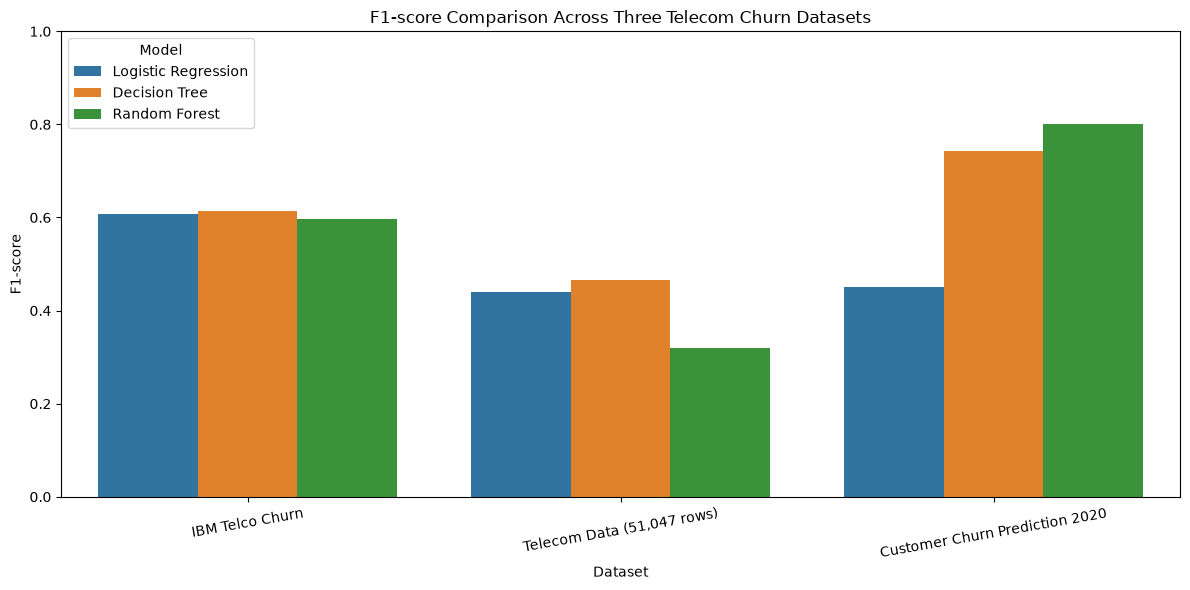

In [38]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))

sns.barplot(
    data=all_results,
    x="Dataset",
    y="F1-score",
    hue="Model"
)

plt.title("F1-score Comparison Across Three Telecom Churn Datasets")
plt.ylabel("F1-score")
plt.xlabel("Dataset")
plt.ylim(0, 1)
plt.xticks(rotation=10)
plt.tight_layout()
plt.show()

In [39]:
from pathlib import Path

model_folder = Path("../models")
model_folder.mkdir(parents=True, exist_ok=True)

print("Saved model files:")
for file in sorted(model_folder.glob("*.joblib")):
    print(f"{file.name} — {file.stat().st_size / 1024:.1f} KB")

Saved model files:
dataset2_decision_tree.joblib — 53.0 KB
dataset2_logistic_regression.joblib — 27.4 KB
dataset2_random_forest.joblib — 263705.3 KB
dataset3_decision_tree.joblib — 19.2 KB
dataset3_logistic_regression.joblib — 6.8 KB
dataset3_random_forest.joblib — 7696.5 KB
decision_tree.joblib — 17.8 KB
logistic_regression.joblib — 8.3 KB
random_forest.joblib — 39644.9 KB


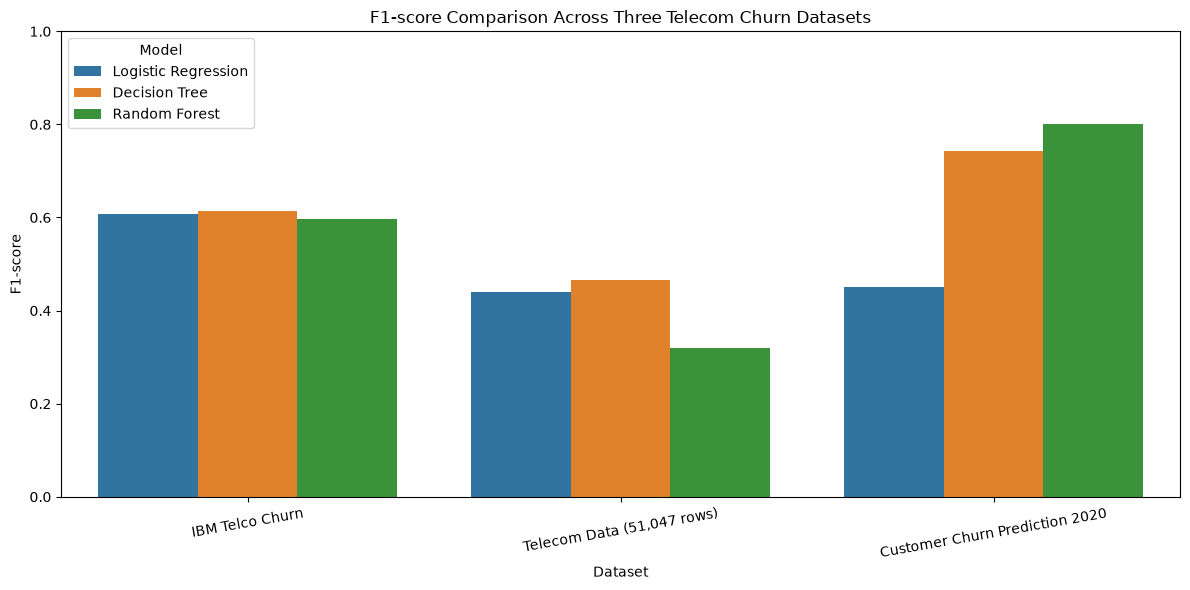

Saved comparison CSV and graph in: C:\Users\LAPTOP\Desktop\Telecom-Customer-Churn-Prediction\reports


In [40]:
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns

reports_folder = Path("../reports")
reports_folder.mkdir(parents=True, exist_ok=True)

# Save metrics
all_results.to_csv(
    reports_folder / "model_comparison_all_datasets.csv",
    index=False
)

# Save graph
plt.figure(figsize=(12, 6))
sns.barplot(
    data=all_results,
    x="Dataset",
    y="F1-score",
    hue="Model"
)
plt.title("F1-score Comparison Across Three Telecom Churn Datasets")
plt.ylabel("F1-score")
plt.xlabel("Dataset")
plt.ylim(0, 1)
plt.xticks(rotation=10)
plt.tight_layout()
plt.savefig(
    reports_folder / "f1_score_comparison.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

print("Saved comparison CSV and graph in:", reports_folder.resolve())

In [41]:
from pathlib import Path
import joblib

model_folder = Path("../models")

print("MODEL FILE VERIFICATION")
print("Model folder:", model_folder.resolve())
print("Folder exists:", model_folder.exists())

if model_folder.exists():
    model_files = sorted(model_folder.glob("*.joblib"))

    for file in model_files:
        try:
            model = joblib.load(file)
            print(f"PASS: {file.name} — loaded successfully")
        except Exception as e:
            print(f"FAIL: {file.name} — {e}")

    print("\nTotal saved model files:", len(model_files))
else:
    print("Model folder not found. We need to check the folder path.")

MODEL FILE VERIFICATION
Model folder: C:\Users\LAPTOP\Desktop\Telecom-Customer-Churn-Prediction\models
Folder exists: True
PASS: dataset2_decision_tree.joblib — loaded successfully
PASS: dataset2_logistic_regression.joblib — loaded successfully
PASS: dataset2_random_forest.joblib — loaded successfully
PASS: dataset3_decision_tree.joblib — loaded successfully
PASS: dataset3_logistic_regression.joblib — loaded successfully
PASS: dataset3_random_forest.joblib — loaded successfully
PASS: decision_tree.joblib — loaded successfully
PASS: logistic_regression.joblib — loaded successfully
PASS: random_forest.joblib — loaded successfully

Total saved model files: 9


In [42]:
import pandas as pd
from pathlib import Path

prediction_file = Path("../data/processed/dataset3_predictions.csv")

if prediction_file.exists():
    predictions = pd.read_csv(prediction_file)

    print("Prediction file verified!")
    print("Shape:", predictions.shape)
    print("Columns:", predictions.columns.tolist())
    print("\nPrediction counts:")
    print(predictions["churn"].value_counts())
    print("\nFirst five predictions:")
    display(predictions.head())

    assert len(predictions) == 750, "Expected 750 predictions"
    assert predictions["churn"].isin(["yes", "no"]).all()

    print("\nPASS: All 750 predictions have valid labels.")
else:
    print("Prediction file not found. We need to check its path.")

Prediction file verified!
Shape: (750, 2)
Columns: ['id', 'churn']

Prediction counts:
churn
no     649
yes    101
Name: count, dtype: int64

First five predictions:


,id,churn
0,1,no
1,2,no
2,3,yes
3,4,no
4,5,no



PASS: All 750 predictions have valid labels.


In [43]:
from pathlib import Path
import joblib

model_folder = Path("../models")

print("Model folder:", model_folder.resolve())
print("Folder exists:", model_folder.exists())

if model_folder.exists():
    model_files = sorted(model_folder.glob("*.joblib"))

    for file in model_files:
        try:
            joblib.load(file)
            print("PASS:", file.name)
        except Exception as e:
            print("FAIL:", file.name, "-", e)

    print("\nTotal saved model files:", len(model_files))
else:
    print("Model folder not found. We need to check the path.")

Model folder: C:\Users\LAPTOP\Desktop\Telecom-Customer-Churn-Prediction\models
Folder exists: True
PASS: dataset2_decision_tree.joblib
PASS: dataset2_logistic_regression.joblib
PASS: dataset2_random_forest.joblib
PASS: dataset3_decision_tree.joblib
PASS: dataset3_logistic_regression.joblib
PASS: dataset3_random_forest.joblib
PASS: decision_tree.joblib
PASS: logistic_regression.joblib
PASS: random_forest.joblib

Total saved model files: 9


In [44]:
import joblib
import numpy as np
from pathlib import Path

model_path = Path("../models/dataset3_random_forest.joblib")

# Reload the saved model
loaded_model = joblib.load(model_path)

# Predict using the existing held-out test set
saved_predictions = loaded_model.predict(X3_test)
saved_probabilities = loaded_model.predict_proba(X3_test)[:, 1]

print("Saved model loaded successfully!")
print("Test records evaluated:", len(X3_test))
print("Predictions generated:", len(saved_predictions))
print("Probability range:",
      round(saved_probabilities.min(), 4),
      "to",
      round(saved_probabilities.max(), 4))

print("\nAccuracy from reloaded model:",
      round((saved_predictions == y3_test).mean(), 4))

print("\nFirst 10 predictions:")
print(saved_predictions[:10])

Saved model loaded successfully!
Test records evaluated: 850
Predictions generated: 850
Probability range: 0.0 to 0.98

Accuracy from reloaded model: 0.9482

First 10 predictions:
[0 0 0 0 0 0 0 0 0 0]


RELOADED RANDOM FOREST — FINAL EVALUATION

              precision    recall  f1-score   support

      Stayed     0.9573    0.9836    0.9703       730
     Churned     0.8800    0.7333    0.8000       120

    accuracy                         0.9482       850
   macro avg     0.9187    0.8584    0.8851       850
weighted avg     0.9464    0.9482    0.9462       850

ROC-AUC: 0.8887


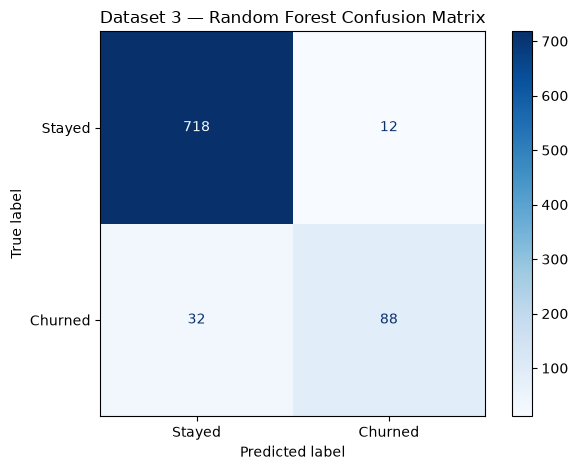

In [45]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

print("RELOADED RANDOM FOREST — FINAL EVALUATION\n")

print(classification_report(
    y3_test,
    saved_predictions,
    target_names=["Stayed", "Churned"],
    digits=4
))

print("ROC-AUC:",
      round(roc_auc_score(y3_test, saved_probabilities), 4))

cm = confusion_matrix(y3_test, saved_predictions)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Stayed", "Churned"]
).plot(cmap="Blues", values_format="d")

plt.title("Dataset 3 — Random Forest Confusion Matrix")
plt.tight_layout()
plt.show()

In [46]:
from pathlib import Path
import pandas as pd
import joblib

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, classification_report,
    confusion_matrix
)

reports_folder = Path("../reports")
reports_folder.mkdir(parents=True, exist_ok=True)

# Final metrics from the reloaded saved model
final_metrics = pd.DataFrame([{
    "Dataset": "Customer Churn Prediction 2020",
    "Model": "Random Forest",
    "Accuracy": accuracy_score(y3_test, saved_predictions),
    "Precision": precision_score(
        y3_test, saved_predictions, zero_division=0
    ),
    "Recall": recall_score(
        y3_test, saved_predictions, zero_division=0
    ),
    "F1-score": f1_score(
        y3_test, saved_predictions, zero_division=0
    ),
    "ROC-AUC": roc_auc_score(y3_test, saved_probabilities)
}])

final_metrics.to_csv(
    reports_folder / "dataset3_random_forest_final_metrics.csv",
    index=False
)

# Save the confusion matrix
cm = confusion_matrix(y3_test, saved_predictions)

pd.DataFrame(
    cm,
    index=["Actual Stayed", "Actual Churned"],
    columns=["Predicted Stayed", "Predicted Churned"]
).to_csv(reports_folder / "dataset3_confusion_matrix.csv")

# Save the classification report
report = classification_report(
    y3_test,
    saved_predictions,
    target_names=["Stayed", "Churned"],
    digits=4
)

(reports_folder / "dataset3_classification_report.txt").write_text(
    report, encoding="utf-8"
)

print("Final evaluation files saved successfully:")
for file in sorted(reports_folder.glob("dataset3_*")):
    print(file.name)

display(final_metrics.round(4))

Final evaluation files saved successfully:
dataset3_classification_report.txt
dataset3_confusion_matrix.csv
dataset3_random_forest_final_metrics.csv


,Dataset,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Customer Churn Prediction 2020,Random Forest,0.9482,0.88,0.7333,0.8,0.8887


In [47]:
from pathlib import Path

project_folder = Path("..").resolve()

required_paths = [
    "data/raw",
    "data/processed",
    "models",
    "reports",
    "README.md",
    "requirements.txt",
    ".gitignore",
]

print("Project folder:", project_folder)
print("\nPATH VERIFICATION")

for item in required_paths:
    path = project_folder / item
    print(f"{'PASS' if path.exists() else 'MISSING'}: {item}")

print("\nSaved model count:",
      len(list((project_folder / "models").glob("*.joblib"))))

print("Raw CSV count:",
      len(list((project_folder / "data/raw").glob("*.csv"))))

Project folder: C:\Users\LAPTOP\Desktop\Telecom-Customer-Churn-Prediction

PATH VERIFICATION
PASS: data/raw
PASS: data/processed
PASS: models
PASS: reports
PASS: README.md
PASS: requirements.txt
PASS: .gitignore

Saved model count: 9
Raw CSV count: 6


In [48]:
# Explainability: Random Forest Feature Importance

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import joblib

project_folder = Path("..").resolve()

# Load the existing trained model
model_path = project_folder / "models" / "dataset3_random_forest.joblib"
model = joblib.load(model_path)

# Use the features already prepared for Dataset 3
feature_names = X3_test.columns

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": model.feature_importances_
}).sort_values("Importance", ascending=False)

# Display the top 15 features
display(importance_df.head(15))

# Save the results
reports_folder = project_folder / "reports"
reports_folder.mkdir(exist_ok=True)

importance_df.to_csv(
    reports_folder / "dataset3_feature_importance.csv",
    index=False
)

# Plot the top 15 features
top_features = importance_df.head(15).sort_values("Importance")

plt.figure(figsize=(10, 7))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Top 15 Features Influencing Dataset 3 Churn Predictions")
plt.tight_layout()

plt.savefig(
    reports_folder / "dataset3_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Feature importance CSV and graph saved successfully.")

AttributeError: 'Pipeline' object has no attribute 'feature_importances_'

,Feature,Importance
4,numeric__total_day_charge,0.129962
14,numeric__number_customer_service_calls,0.126883
2,numeric__total_day_minutes,0.121727
69,categorical__international_plan_no,0.050919
7,numeric__total_eve_charge,0.050045
5,numeric__total_eve_minutes,0.048647
70,categorical__international_plan_yes,0.047004
11,numeric__total_intl_minutes,0.036427
13,numeric__total_intl_charge,0.035818
8,numeric__total_night_minutes,0.034917


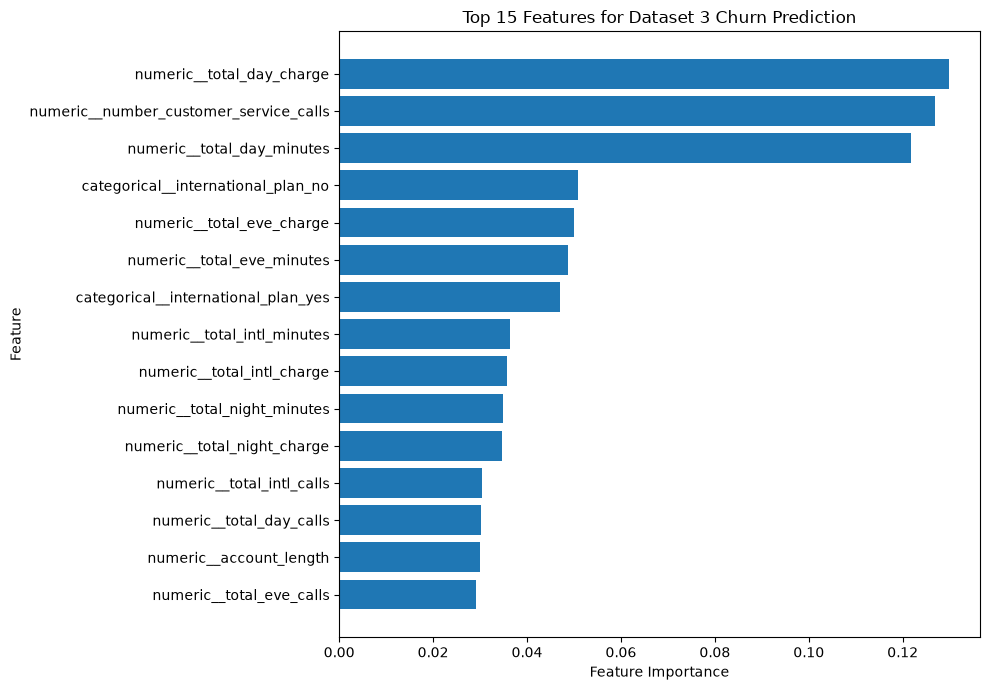

Feature importance CSV and graph saved successfully.


In [49]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import joblib

project_folder = Path("..").resolve()
reports_folder = project_folder / "reports"
reports_folder.mkdir(exist_ok=True)

# Load existing model
model = joblib.load(
    project_folder / "models" / "dataset3_random_forest.joblib"
)

# Find the Random Forest inside the Pipeline
rf_model = model.named_steps.get("classifier")

if rf_model is None:
    rf_model = model.named_steps.get("randomforestclassifier")

if rf_model is None:
    rf_model = next(
        (step for step in model.named_steps.values()
         if hasattr(step, "feature_importances_")),
        None
    )

if rf_model is None:
    raise ValueError(
        "No Random Forest feature importance found. "
        "Check the pipeline steps."
    )

# Get the feature names expected by the model
try:
    feature_names = model[:-1].get_feature_names_out()
except (AttributeError, ValueError):
    feature_names = X3_test.columns

# Match feature names to importance values
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_model.feature_importances_
}).sort_values("Importance", ascending=False)

display(importance_df.head(15))

# Save results
importance_df.to_csv(
    reports_folder / "dataset3_feature_importance.csv",
    index=False
)

# Plot top 15 features
top_features = importance_df.head(15).sort_values("Importance")

plt.figure(figsize=(10, 7))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Top 15 Features for Dataset 3 Churn Prediction")
plt.tight_layout()

plt.savefig(
    reports_folder / "dataset3_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Feature importance CSV and graph saved successfully.")

In [50]:
from pathlib import Path

reports_folder = Path("../reports")

for filename in [
    "dataset3_feature_importance.csv",
    "dataset3_feature_importance.png"
]:
    path = reports_folder / filename
    print("PASS" if path.exists() else "MISSING", "-", path.name)

PASS - dataset3_feature_importance.csv
PASS - dataset3_feature_importance.png


In [51]:
from pathlib import Path

reports_folder = Path("../reports").resolve()

files_to_check = [
    "dataset3_feature_importance.csv",
    "dataset3_feature_importance.png",
    "model_comparison_all_datasets.csv",
    "dataset3_random_forest_final_metrics.csv",
    "dataset3_confusion_matrix.csv",
    "dataset3_classification_report.txt",
]

for filename in files_to_check:
    path = reports_folder / filename
    print(f"{'PASS' if path.exists() else 'MISSING'}: {filename}")

PASS: dataset3_feature_importance.csv
PASS: dataset3_feature_importance.png
PASS: model_comparison_all_datasets.csv
PASS: dataset3_random_forest_final_metrics.csv
PASS: dataset3_confusion_matrix.csv
PASS: dataset3_classification_report.txt


In [52]:
from pathlib import Path
import pandas as pd

project = Path("..").resolve()

print("PROJECT:", project)

# Check essential files
required_files = [
    "README.md",
    "requirements.txt",
    "data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv",
    "data/raw/Telecom Data.csv",
    "data/raw/train.csv",
    "data/raw/test.csv",
    "data/processed/dataset3_predictions.csv",
    "reports/model_comparison_all_datasets.csv",
    "reports/dataset3_feature_importance.csv",
    "reports/dataset3_feature_importance.png",
]

print("\nFILE CHECK")
for filename in required_files:
    path = project / filename
    print(f"{'PASS' if path.exists() else 'MISSING'}: {filename}")

# Check saved model files
models = list((project / "models").glob("*.joblib"))
print("\nSaved model count:", len(models))

# Inspect model comparison results
comparison_path = (
    project / "reports" / "model_comparison_all_datasets.csv"
)

if comparison_path.exists():
    comparison = pd.read_csv(comparison_path)
    print("\nComparison table shape:", comparison.shape)
    display(comparison.head())

# Check the saved 750 predictions
predictions_path = (
    project / "data" / "processed" / "dataset3_predictions.csv"
)

if predictions_path.exists():
    predictions = pd.read_csv(predictions_path)
    print("\nPrediction table shape:", predictions.shape)
    display(predictions.head())

PROJECT: C:\Users\LAPTOP\Desktop\Telecom-Customer-Churn-Prediction

FILE CHECK
PASS: README.md
PASS: requirements.txt
PASS: data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv
PASS: data/raw/Telecom Data.csv
PASS: data/raw/train.csv
PASS: data/raw/test.csv
PASS: data/processed/dataset3_predictions.csv
PASS: reports/model_comparison_all_datasets.csv
PASS: reports/dataset3_feature_importance.csv
PASS: reports/dataset3_feature_importance.png

Saved model count: 9

Comparison table shape: (9, 7)


,Dataset,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,IBM Telco Churn,Logistic Regression,0.803838,0.648485,0.572193,0.607955,0.835929
1,IBM Telco Churn,Decision Tree,0.733475,0.499165,0.799465,0.614594,0.818165
2,IBM Telco Churn,Random Forest,0.767591,0.553531,0.649733,0.597786,0.814587
3,"Telecom Data (51,047 rows)",Logistic Regression,0.579334,0.356583,0.571720,0.439222,0.611701
4,"Telecom Data (51,047 rows)",Decision Tree,0.591969,0.373554,0.614548,0.464662,0.631903



Prediction table shape: (750, 2)


,id,churn
0,1,no
1,2,no
2,3,yes
3,4,no
4,5,no


TELECOM CUSTOMER CHURN PREDICTION
FINAL MODEL DEMONSTRATION


,Dataset,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
8,Customer Churn Prediction 2020,Random Forest,0.948235,0.880000,0.733333,0.800000,0.888664
7,Customer Churn Prediction 2020,Decision Tree,0.929412,0.763158,0.725000,0.743590,0.815074
1,IBM Telco Churn,Decision Tree,0.733475,0.499165,0.799465,0.614594,0.818165
0,IBM Telco Churn,Logistic Regression,0.803838,0.648485,0.572193,0.607955,0.835929
2,IBM Telco Churn,Random Forest,0.767591,0.553531,0.649733,0.597786,0.814587
4,"Telecom Data (51,047 rows)",Decision Tree,0.591969,0.373554,0.614548,0.464662,0.631903
6,Customer Churn Prediction 2020,Logistic Regression,0.754118,0.329502,0.716667,0.451444,0.792557
3,"Telecom Data (51,047 rows)",Logistic Regression,0.579334,0.356583,0.571720,0.439222,0.611701
5,"Telecom Data (51,047 rows)",Random Forest,0.707052,0.483092,0.237933,0.318834,0.658597



Loaded saved model: dataset3_random_forest.joblib

FINAL EVALUATION METRICS
Accuracy : 0.9482
Precision: 0.8800
Recall   : 0.7333
F1-score : 0.8000
ROC-AUC  : 0.8887

CONFUSION MATRIX
[[718  12]
 [ 32  88]]


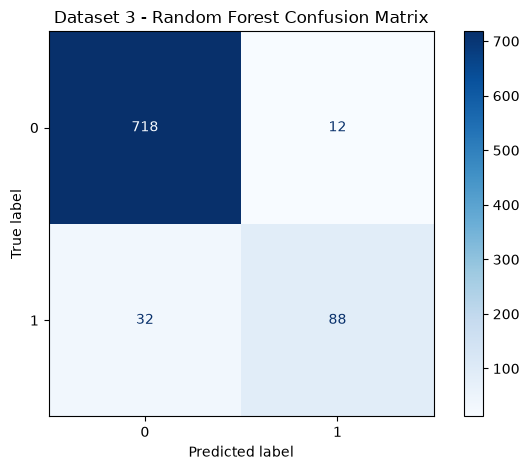


CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0       0.96      0.98      0.97       730
           1       0.88      0.73      0.80       120

    accuracy                           0.95       850
   macro avg       0.92      0.86      0.89       850
weighted avg       0.95      0.95      0.95       850


FEATURE IMPORTANCE


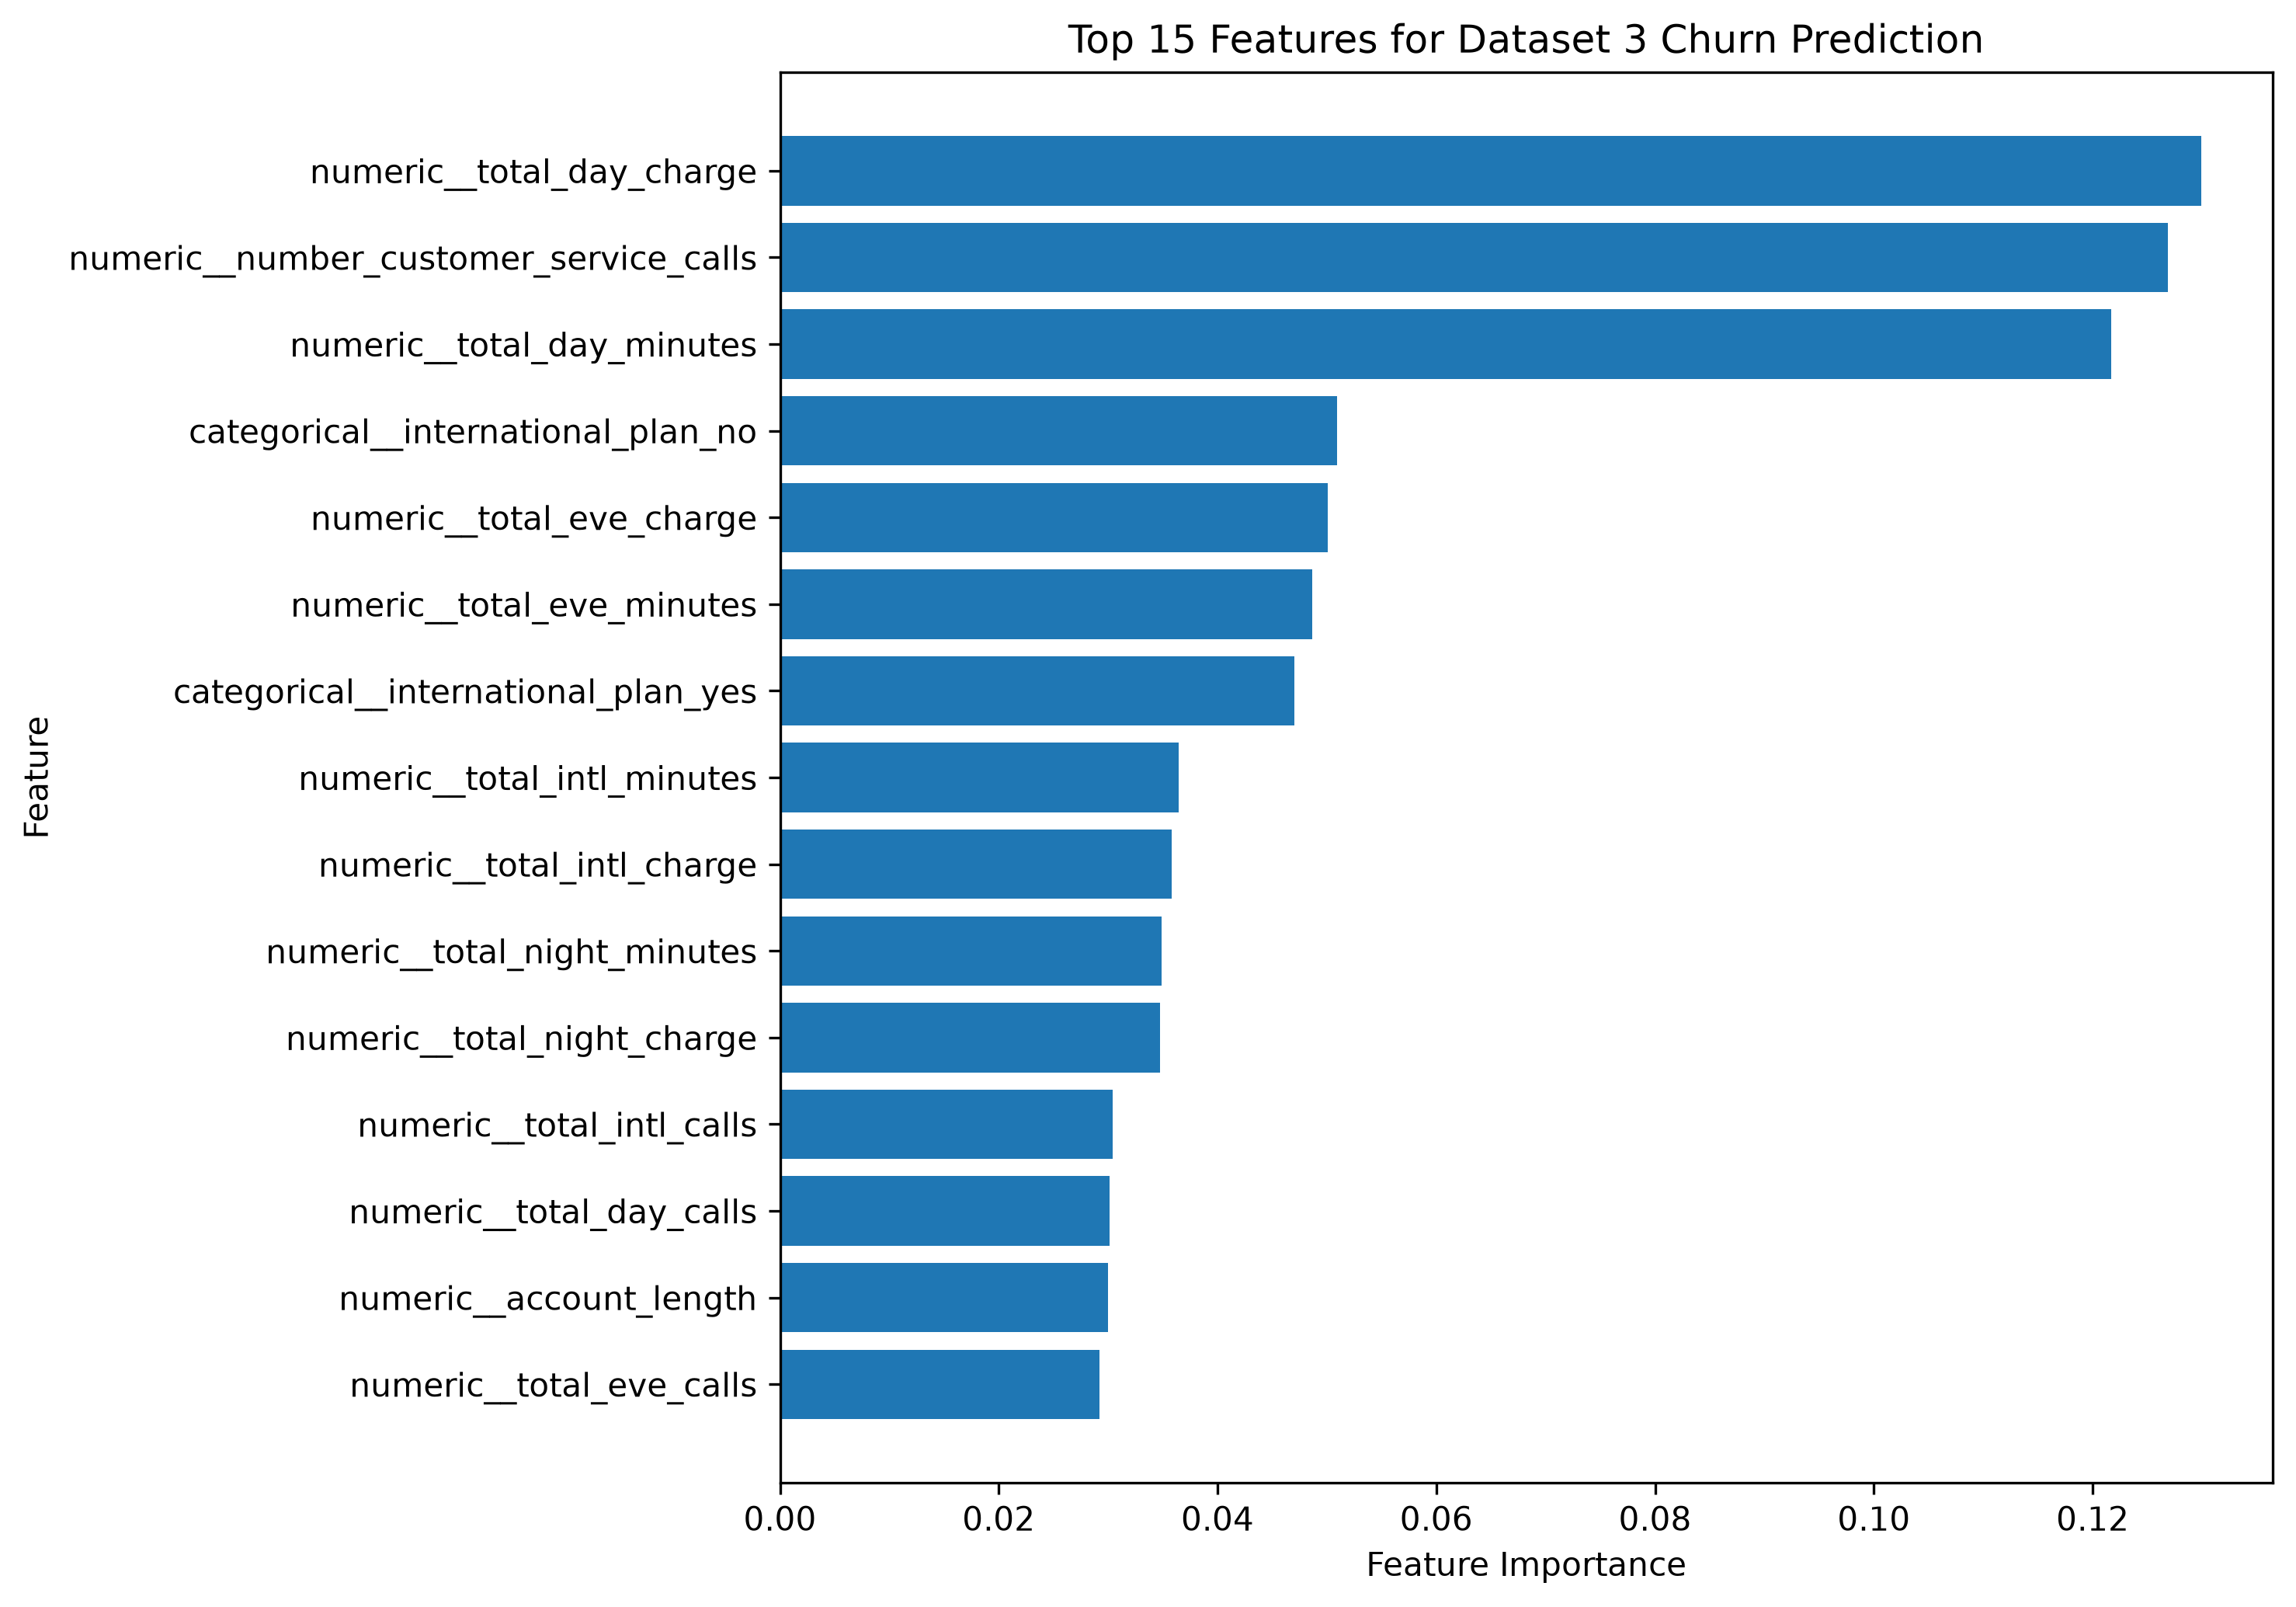


SAMPLE CUSTOMER PREDICTION
Predicted churn class: 0
Class probabilities:
  Class 0: 96.67%
  Class 1: 3.33%

FINAL MODEL DEMONSTRATION COMPLETED


In [53]:
# FINAL MODEL DEMONSTRATION
from pathlib import Path
import joblib
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)
from IPython.display import display, Image

# Project paths
project = Path("..").resolve()
reports = project / "reports"

# 1. Show model comparison
print("=" * 60)
print("TELECOM CUSTOMER CHURN PREDICTION")
print("FINAL MODEL DEMONSTRATION")
print("=" * 60)

comparison = pd.read_csv(
    reports / "model_comparison_all_datasets.csv"
)
display(comparison.sort_values("F1-score", ascending=False))

# 2. Load the saved Random Forest model
model_path = project / "models" / "dataset3_random_forest.joblib"
model = joblib.load(model_path)

print("\nLoaded saved model:", model_path.name)

# 3. Evaluate on the existing held-out test split
y_true = y3_test
y_pred = model.predict(X3_test)

print("\nFINAL EVALUATION METRICS")
print(f"Accuracy : {accuracy_score(y_true, y_pred):.4f}")
print(f"Precision: {precision_score(y_true, y_pred, zero_division=0):.4f}")
print(f"Recall   : {recall_score(y_true, y_pred, zero_division=0):.4f}")
print(f"F1-score : {f1_score(y_true, y_pred, zero_division=0):.4f}")

if hasattr(model, "predict_proba"):
    probabilities = model.predict_proba(X3_test)
    classes = list(model.classes_)

    if len(classes) == 2:
        positive_class = 1 if 1 in classes else classes[-1]
        positive_index = classes.index(positive_class)
        y_binary = (pd.Series(y_true).to_numpy() == positive_class).astype(int)

        print(
            "ROC-AUC  :",
            f"{roc_auc_score(y_binary, probabilities[:, positive_index]):.4f}"
        )

# 4. Confusion matrix
cm = confusion_matrix(y_true, y_pred, labels=model.classes_)

print("\nCONFUSION MATRIX")
print(cm)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=model.classes_
).plot(cmap="Blues", values_format="d")

plt.title("Dataset 3 - Random Forest Confusion Matrix")
plt.tight_layout()
plt.show()

# 5. Detailed classification report
print("\nCLASSIFICATION REPORT")
print(classification_report(y_true, y_pred, zero_division=0))

# 6. Show explainability graph
importance_image = reports / "dataset3_feature_importance.png"

if importance_image.exists():
    print("\nFEATURE IMPORTANCE")
    display(Image(filename=str(importance_image)))
else:
    print("Feature-importance image not found:", importance_image)

# 7. Demonstrate one held-out customer prediction
print("\nSAMPLE CUSTOMER PREDICTION")
sample = X3_test.iloc[[0]]
sample_prediction = model.predict(sample)[0]

print("Predicted churn class:", sample_prediction)

if hasattr(model, "predict_proba"):
    sample_probabilities = model.predict_proba(sample)[0]
    print("Class probabilities:")
    for class_label, probability in zip(model.classes_, sample_probabilities):
        print(f"  Class {class_label}: {probability:.2%}")

print("\nFINAL MODEL DEMONSTRATION COMPLETED")